# The Wirtinger gradient and Adam's step: a gradient through any forward model

**Question:** How does a gradient taken through the forward model reach the phase of every pixel, what does Adam do to it, and what does the choice of forward model change in the result?

- Level: 2, the method in practice.
- Prerequisites: `05-optimization/01-the-cost-and-its-gradient`, which introduces the cost and checks its gradient.
- Reading time: about 25 minutes. The notebook runs in about a minute and a half.

## Objectives

M11 is the optimiser that machine-learning holography uses: take the derivative of a loss through whatever model turns phase into light, and let Adam move the phase. Its attraction is generality, because the same code works for any forward model that has an adjoint. Its risk is a step size that is easy to set badly. This notebook opens both. By the end you can:

- state the Wirtinger pull-back and say why a phase-only hologram needs only one real gradient per pixel;
- check that the gradient survives a change of forward model, here a pixel-crosstalk device, and say where a finite-difference check stops being valid;
- explain what Adam does to a gradient whose scale you cannot predict, with the first step as evidence;
- choose a learning rate from a sweep rather than from a paper;
- show what the choice of forward model does to a hologram displayed on a device.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.device import Device
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.optim import m11_wirtinger_adam
from pipeline.model.holo.methods.optim.costs import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C12 of `data/examples/cases.json`, the same 10 x 10 calibration task as the previous notebook.

- Owner: this repository; the case is synthetic and follows the task of Di Leonardo, Ianni and Ruocco (2007).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C12.

In [2]:
# case C12: the optical setup and the 100 traps of the 10 x 10 task
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
n = setup.n_pix
print(rec["case_id"], "|", len(target.traps), "traps | SLM", n, "x", n, "pixels")

C12_calibration | 100 traps | SLM 256 x 256 pixels


## Method

### Step 1: the pull-back, and a forward model that is not the ideal one

For a real loss $L(I)$ of the intensities $I = |z|^2$, with $z$ the complex field at the traps, the derivative with respect to the real and imaginary parts of $z$ combines into one complex number, the Wirtinger gradient $G = \partial L / \partial z^* = L'(I)\,z$. If $z = \mathrm{Op}(f)$ is a linear function of the SLM field $f_j = A_j e^{i\phi_j}$, the chain rule gives the derivative with respect to each phase, $\partial L / \partial \phi_j = 2\,\mathrm{Re}\,(i f_j\,\overline{(\mathrm{Op}^H G)_j})$ (Chakravarthula et al., 2019, eqs 5 to 8). Because the SLM is phase-only, $f_j$ carries one real parameter, and the whole gradient is one real number per pixel, computed with one forward and one adjoint application of the model.

Nothing in that derivation says the model is a plain Fourier transform. The pipeline provides the same pull-back for a device whose pixels leak into their neighbours: the phase is upsampled 3 x 3, blurred by the crosstalk kernel of Schroff et al. (2023), transformed, and read at the traps. The cell compares the analytic gradient with central differences through the ideal model and through that device (sigma 1.24 per pixel, exponent 1.8, fill factor 0.85), at four step sizes. The last column counts how many of the 65536 pixels the perturbation pushes across the wrap at 0 and $2\pi$, which matters for the crosstalk model.

In [3]:
# the gradient check of the previous notebook through two forward models: ideal FFT and a crosstalk device
device = Device(crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85)
rng = Rng(8)
phi0 = rng.phases(n**2).reshape(n, n)
direction = rng.normal_array(n**2).reshape(n, n)
direction /= np.linalg.norm(direction)
errors = {}
for name, dev in (("ideal", None), ("crosstalk", device)):
    cost = TrapCost(setup, target.traps, dev, t=2, efficiency=0.9)
    slope = float(np.sum(cost.value_grad(phi0)[1] * direction))
    for h in (1e-1, 1e-2, 1e-3, 1e-4):
        up, down = cost.value_grad(phi0 + h * direction)[0], cost.value_grad(phi0 - h * direction)[0]
        errors[name, h] = abs((up - down) / (2 * h) - slope) / abs(slope)
for h in (1e-1, 1e-2, 1e-3, 1e-4):
    wrapped = int(np.sum((phi0 + h * direction >= 2 * np.pi) | (phi0 + h * direction < 0)))
    print(f"h {h:.0e}: ideal {errors['ideal', h]:.1e} | crosstalk {errors['crosstalk', h]:.1e}")
    print(f"        pixels pushed across the 2 pi wrap: {wrapped}")

h 1e-01: ideal 1.2e-07 | crosstalk 4.5e+02
        pixels pushed across the 2 pi wrap: 2
h 1e-02: ideal 3.5e-10 | crosstalk 3.0e+03
        pixels pushed across the 2 pi wrap: 1
h 1e-03: ideal 4.0e-09 | crosstalk 2.3e-07
        pixels pushed across the 2 pi wrap: 0
h 1e-04: ideal 6.9e-08 | crosstalk 7.4e-06
        pixels pushed across the 2 pi wrap: 0


Through the ideal model the analytic gradient is right at every step, with a relative error between 3.5e-10 and 1.2e-7. Through the crosstalk device it is right to 2.3e-07 at h = 0.001 and to 7.4e-06 at h = 0.0001, so the same pull-back holds for a forward model with an upsampling, a kernel convolution and a pixel aperture in it. At h = 0.1 and h = 0.01 the crosstalk check fails by three orders of magnitude or more, and the last column says why: one or two pixels were pushed across the wrap. The model keeps the phase inside one turn before blurring it, so a pixel pushed across the wrap changes the blurred phase by $2\pi$ in its neighbourhood, and a finite difference that crosses it measures a jump, not a slope. The gradient is not wrong there; the check is outside its validity. A check of this kind should use a step small enough that no pixel crosses a wrap. What it does not test is the quantizer of a real device, whose rounding has zero slope almost everywhere; the pipeline treats it as the identity in the backward pass (a straight-through estimator), and a finite difference would not agree with that by design.

### Step 2: what Adam does to a gradient of unknown scale

The gradient of the normalised cost is tiny and has no natural unit: its median per pixel is of order $10^{-6}$ and would change by orders of magnitude with the number of traps or the target efficiency. Adam (Kingma and Ba, 2015) is built to be indifferent to that scale. It keeps running averages of the gradient and of its square, $m_k = \beta_1 m_{k-1} + (1 - \beta_1) g_k$ and $v_k = \beta_2 v_{k-1} + (1 - \beta_2) g_k^2$, corrects their start-up bias to $\hat m_k$ and $\hat v_k$, and moves each pixel by $\mathrm{lr}\,\hat m_k / (\sqrt{\hat v_k} + \epsilon)$ with $\beta_1 = 0.9$, $\beta_2 = 0.999$ and $\epsilon = 10^{-8}$ in the pipeline. At the very first step $\hat m = g$ and $\hat v = g^2$, so the move is $\mathrm{lr}\,g / (|g| + \epsilon)$: a pixel whose gradient is much larger than $\epsilon$ moves by almost exactly the learning rate, whatever the size of the gradient.

The cell starts both learning rates 0.1 and 1.0 from the same random phase pattern, runs M11 for one iteration, and measures how far every pixel moved.

In [4]:
# the first Adam step of every pixel against the size of its gradient (cost of the ideal model)
cost = TrapCost(setup, target.traps, None, t=2, efficiency=0.9)
grad0 = np.abs(cost.value_grad(phi0)[1]).ravel()
first = {lr: m11_wirtinger_adam.run(setup, target, budget=Budget(1), rng=Rng(1), init=phi0, lr=lr) for lr in (0.1, 1.0)}
moved = {lr: np.abs(np.angle(np.exp(1j * (res.phi - phi0)))).ravel() for lr, res in first.items()}
print(f"median gradient per pixel: {np.median(grad0):.2e}")
for lr, size in moved.items():
    print(f"lr {lr}: median step {np.median(size):.4f} rad | "
          f"largest step {size.max():.4f} rad")

median gradient per pixel: 9.93e-07
lr 0.1: median step 0.0990 rad | largest step 0.0999 rad
lr 1.0: median step 0.9900 rad | largest step 0.9991 rad


The scatter plots the move of 3000 pixels against their gradient, together with the closed form.

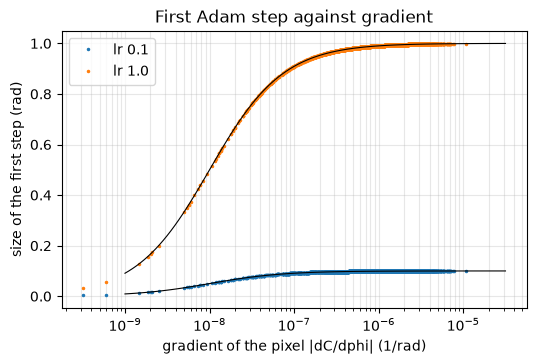

In [5]:
# step size against gradient size for 3000 pixels, with the closed form lr g / (g + eps)
pick = np.random.default_rng(3).choice(grad0.size, 3000, replace=False)
g_axis = np.logspace(-9, -4.5, 100)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for lr, size in moved.items():
    ax.semilogx(grad0[pick], size[pick], ".", markersize=3, label=f"lr {lr}")
    ax.semilogx(g_axis, lr * g_axis / (g_axis + 1e-8), "k-", linewidth=0.8)
ax.set_xlabel("gradient of the pixel |dC/dphi| (1/rad)")
ax.set_ylabel("size of the first step (rad)")
ax.set_title("First Adam step against gradient")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

The points lie on the black curves. For gradients above about $10^{-7}$ the step saturates at the learning rate, 0.1 or 1.0 rad; only the pixels with the smallest gradients, to the left of the knee at $\epsilon = 10^{-8}$, move less. With the median gradient at 9.93e-07 the typical pixel moves 0.99 of the learning rate, so at lr = 1 the first iteration rotates most pixels by almost a full radian, a coarse and large move that the hologram then has to recover from. This is what makes the learning rate the one parameter that matters: Adam has removed the scale of the gradient from the problem and left the step in radians. The figure does not show how the steps behave after the first, when the running averages carry memory and the move shrinks as the gradients agree less from one iteration to the next; the sweep below measures that effect on the result.

### Step 3: choosing the learning rate

The paper of Chakravarthula et al. uses Adam with a learning rate of 0.001 for learned losses. The pipeline records that value as `PAPER_LR` and uses a tuned one, 1.0, for this loss. The cell tests that choice rather than repeating it: four learning rates, 30 iterations each, the same start.

In [6]:
# 30 Wirtinger-Adam iterations at four learning rates; 0.001 is the value of the paper
rates = (0.001, 0.1, 1.0, 4.0)
sweep = {lr: m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(1), lr=lr).history for lr in rates}
for lr, hist in sweep.items():
    last = hist[-1]
    print(f"lr {lr:>5}: efficiency {last['efficiency']:.4f}  "
          f"rel. std {last['rel_std']:7.2f} %  loss {last['loss']:.4f}")

lr 0.001: efficiency 0.0033  rel. std   91.94 %  loss 0.9927
lr   0.1: efficiency 0.6863  rel. std   11.48 %  loss 0.0640
lr   1.0: efficiency 0.7629  rel. std    2.56 %  loss 0.0237
lr   4.0: efficiency 0.4600  rel. std   14.02 %  loss 0.2441


The curves of the same four runs show how each one gets to, or fails to get to, its final value.

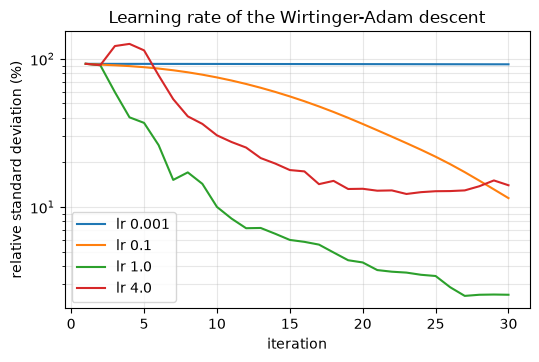

In [7]:
# relative standard deviation of the traps against the iteration, one curve per learning rate
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for lr, hist in sweep.items():
    ax.semilogy([h["iteration"] for h in hist], [h["rel_std"] for h in hist], label=f"lr {lr}")
ax.set_xlabel("iteration")
ax.set_ylabel("relative standard deviation (%)")
ax.set_title("Learning rate of the Wirtinger-Adam descent")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

The sweep has a clear optimum, and it is not the paper's value. At 0.001 the 30 iterations move each pixel by at most 0.03 rad in total, so the hologram is still the random start: efficiency 0.003 and a spread of 91.94 percent. At 0.1 the descent works but is slow, ending at 11.48 percent. At 1.0 it reaches 2.56 percent. At 4.0 the steps are larger than the structure of the phase pattern, the loss rises and the run ends at 14.02 percent with an efficiency of 0.46, worse than the run at 0.1. The curves show that the learning rate trades speed against overshoot in a narrow band. They do not show that 1.0 is best for every task: the pipeline's tuning record chose it on this 10 x 10 task over separate seeds, and a task with 1000 traps would be tuned again. The practical rule is to sweep the rate on a short run before spending a long one.

### Step 4: the forward model decides what the hologram is good for

The check above showed that the gradient is right through the crosstalk device. The question is whether using it matters. The cell optimises M11 for 15 iterations on the ideal model, which is blind to crosstalk, and displays the hologram on the device of the check, scoring it with the pipeline's one scorer.

In [8]:
# M11 optimised on the ideal model, 15 iterations, then displayed on the crosstalk device of the check above
res_ideal = m11_wirtinger_adam.run(setup, target, budget=Budget(15), rng=Rng(1))
on_device = {"ideal model": scoring.score(rec, res_ideal.phi, setup=setup, device=device)}
print(f"ideal model, on the ideal screen: rel. std {res_ideal.history[-1]['rel_std']:.2f} %")
print(f"the same hologram on the device: "
      f"rel. std {list(on_device.values())[0]['rel_std_pct']:.2f} %")

ideal model, on the ideal screen: rel. std 5.99 %
the same hologram on the device: rel. std 14.27 %


The same optimiser is now given the device in its forward model, with the same start, learning rate and number of iterations. Nothing else changes: the pull-back of Step 1 carries the gradient through the upsampling and the kernel.

In [9]:
# M11 with the device in its forward model, the same 15 iterations, scored on the same device
res_aware = m11_wirtinger_adam.run(setup, target, device=device, budget=Budget(15), rng=Rng(1))
on_device["device model"] = scoring.score(rec, res_aware.phi, setup=setup, device=device)
for name, s in on_device.items():
    print(f"{name:18s} efficiency {s['efficiency']:.4f}  rel. std {s['rel_std_pct']:.2f} %")

ideal model        efficiency 0.5956  rel. std 14.27 %
device model       efficiency 0.5724  rel. std 8.68 %


The hologram optimised for the ideal screen has a relative standard deviation of 5.99 percent after 15 iterations, and on the crosstalk device it shows 14.27 percent with an efficiency of 0.5956: the device more than doubles the spread. The same optimiser with the device in its forward model reaches 8.68 percent on that device, at an efficiency of 0.5724, so it removes about two thirds of the spread that the device added and pays 0.0232 of the light for it. Nothing about the optimiser changed, only the model that the gradient is pulled back through, and that is the point of the method: the cost of generality is computation, here a forward and an adjoint of the upsampled model per iteration, and its gain is that the hologram is judged where it is displayed. The comparison is for 15 iterations, one seed and one device; it does not say how much a longer run recovers, and it does not include the quantizer, whose straight-through gradient the check above could not test.

## Results

**Answer:** A gradient through the forward model reaches the phase of every pixel because the Wirtinger pull-back gives one exact derivative per pixel for any linear model, and Adam turns that derivative into a step whose size is the learning rate alone. The derivative is exact: it matches central differences to 3.5e-10 through the ideal model at h = 0.01 and to 2.3e-07 through a crosstalk device at h = 0.001. The learning rate decides how far the descent gets: at 30 iterations the relative standard deviation of the traps is 91.94 percent at the paper's 0.001, 11.48 at 0.1, 2.56 at 1.0 and 14.02 at 4.0. The forward model decides what the hologram is good for: optimised on the ideal screen, a hologram has 5.99 percent spread and shows 14.27 percent on the crosstalk device, and the same 15 iterations with the device in the forward model give 8.68 percent there.

What the notebook did not test is the straight-through quantizer, a longer run on the device, or a target other than the 10 x 10 task.

## Summary

- The Wirtinger pull-back gives the phase gradient of any loss through any linear forward model, one real number per pixel.
- The gradient stays exact through a crosstalk device; a finite-difference check of such a model must keep the step below the size that pushes pixels across the phase wrap.
- Adam normalises the scale of the gradient away, so its first step is the learning rate itself for nearly every pixel.
- The learning rate has a narrow optimum on this task, 1.0, and the paper's 0.001 does not move the hologram in 30 iterations.
- Giving the optimiser the device in its forward model is the whole of the device-aware method; the hologram it returns is judged on the device, not on the ideal screen.

## References

- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539
- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Kingma and Ba (2015). Adam: a method for stochastic optimization. https://arxiv.org/abs/1412.6980